## Question 1a)

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KernelDensity

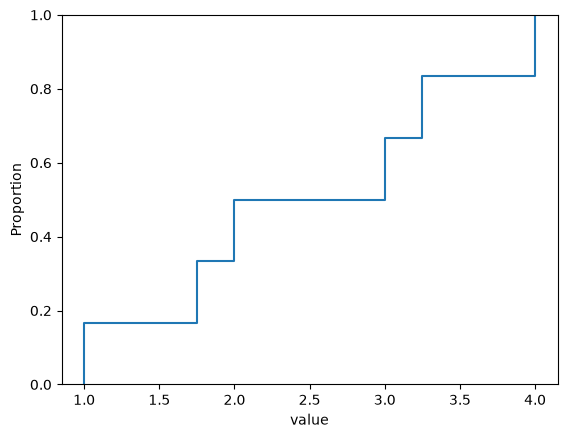

In [6]:
data = [1, 1.75, 2, 3, 3.25, 4]

dataframe = pd.DataFrame({"value" : data})

sns.ecdfplot(data = dataframe, x = "value")

plt.show()

## 1.b)

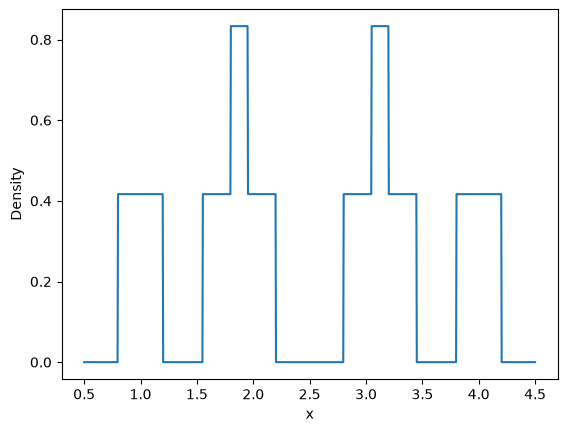

In [9]:
x_data = np.array(data).reshape(-1, 1)

kde = KernelDensity(kernel="tophat", bandwidth=0.2)
kde.fit(x_data)

x = np.linspace(0.5, 4.5, 1000).reshape(-1, 1)
density = np.exp(kde.score_samples(x))

plt.plot(x, density)
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

## 1C)

In [10]:
data = np.array([1, 1.75, 2, 3, 3.25, 4])

SD = np.std(data, ddof=1)
n = len(data)

h = 1.84 * SD * n**(-0.2)

print(SD)
print(h)

1.1067971810589328
1.4231661885912126


## 1D)

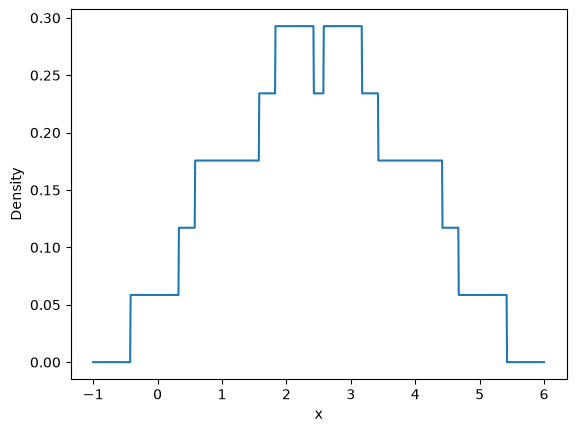

In [11]:
x_data = data.reshape(-1, 1)

kde = KernelDensity(kernel="tophat", bandwidth=h)
kde.fit(x_data)

x = np.linspace(-1, 6, 1000).reshape(-1, 1)
density = np.exp(kde.score_samples(x))

plt.plot(x, density)
plt.xlabel("x")
plt.ylabel("Density")
plt.show()

## 1E)

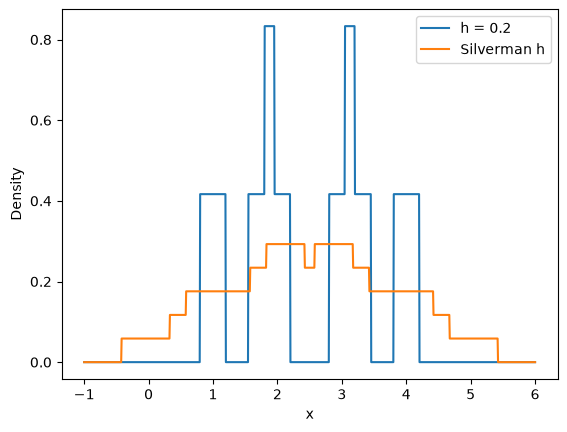

In [12]:
x_data = data.reshape(-1, 1)
x = np.linspace(-1, 6, 1000).reshape(-1, 1)

kde_b = KernelDensity(kernel="tophat", bandwidth=0.2)
kde_b.fit(x_data)
density_b = np.exp(kde_b.score_samples(x))

kde_d = KernelDensity(kernel="tophat", bandwidth=h)
kde_d.fit(x_data)
density_d = np.exp(kde_d.score_samples(x))

plt.plot(x, density_b, label="h = 0.2")
plt.plot(x, density_d, label="Silverman h")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.show()

# Question 2

## 2a)

In [13]:
import numpy as np
from scipy.stats import norm

X = np.array([-1, -0.5, 0, 0.5, 1])

In [14]:
X = np.array([-1, -0.5, 0, 0.5, 1])

x = 0
h = 0.6
n = len(X)

inside = np.abs(X - x) <= h
f_hat = np.sum(inside) / (2 * n * h)

print(inside)
print(f_hat)

[False  True  True  True False]
0.5


## 2b)

In [16]:
h = 0.6

prob = norm.cdf(h) - norm.cdf(-h)

expected_f_hat = prob / (2 * h)

print(prob)
print(expected_f_hat)

norm.cdf(0.6) - norm.cdf(-0.6)

0.45149376449985285
0.3762448037498774


np.float64(0.45149376449985285)

## 2C)

In [17]:
true_density = norm.pdf(0)

print(true_density)

0.3989422804014327


## 2D)

In [18]:
bias = expected_f_hat - true_density

print(bias)

-0.022697476651555304


## 2E)

In [19]:
h = 0.1

prob = norm.cdf(h) - norm.cdf(-h)

expected_small_h = prob / (2 * h)

print(expected_small_h)

0.3982783727702899


In [20]:
true_density = norm.pdf(0)

gap = expected_small_h - true_density

print(true_density)
print(gap)

0.3989422804014327
-0.0006639076311428238


# 3)

## 3a)

In [21]:
import numpy as np
from scipy.stats import norm

X = np.array([5, 7, 7, 8, 10])
h = 1.5

x_values = [6.0, 6.5, 7.0, 8.0, 8.5]

In [22]:
n = len(X)

for x in x_values:
    inside = np.abs(X - x) <= h
    f_hat = np.sum(inside) / (2 * n * h)

    print(x, f_hat)

6.0 0.2
6.5 0.26666666666666666
7.0 0.2
8.0 0.2
8.5 0.26666666666666666


## 3B

In [23]:
for x in x_values:
    z = (x - X) / h
    f_hat = np.sum(norm.pdf(z)) / (len(X) * h)

    print(x, f_hat)

6.0 0.15116667696891303
6.5 0.16865730580239766
7.0 0.17804448100191994
8.0 0.16744524435137584
8.5 0.1506023053792177


## 3C

In [24]:
uniform_values = []

for x in x_values:
    inside = np.abs(X - x) <= h
    f_hat = np.sum(inside) / (2 * len(X) * h)
    uniform_values.append(f_hat)

print(np.diff(uniform_values))

[ 0.06666667 -0.06666667  0.          0.06666667]


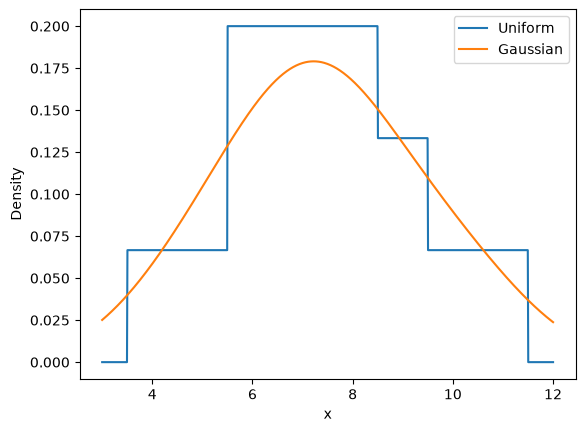

In [25]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KernelDensity

grid = np.linspace(3, 12, 1000).reshape(-1, 1)
X_2d = X.reshape(-1, 1)

uniform = KernelDensity(kernel="tophat", bandwidth=1.5)
uniform.fit(X_2d)
uniform_density = np.exp(uniform.score_samples(grid))

gaussian = KernelDensity(kernel="gaussian", bandwidth=1.5)
gaussian.fit(X_2d)
gaussian_density = np.exp(gaussian.score_samples(grid))

plt.plot(grid, uniform_density, label="Uniform")
plt.plot(grid, gaussian_density, label="Gaussian")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.show()

# 4

## a

In [27]:
df2 = pd.read_csv("/Users/rayyansiddiqui/Documents/DATA_SCIENCE/DS5030/UU_F26_templates/data/heart_failure_clinical_records_dataset.csv")

df2

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


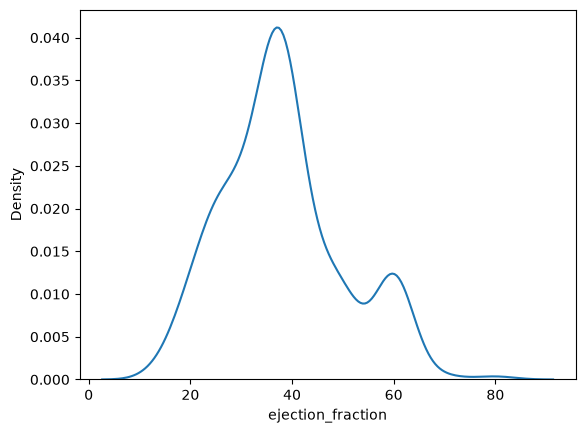

In [29]:
sns.kdeplot(data = df2, x = "ejection_fraction")
plt.show()

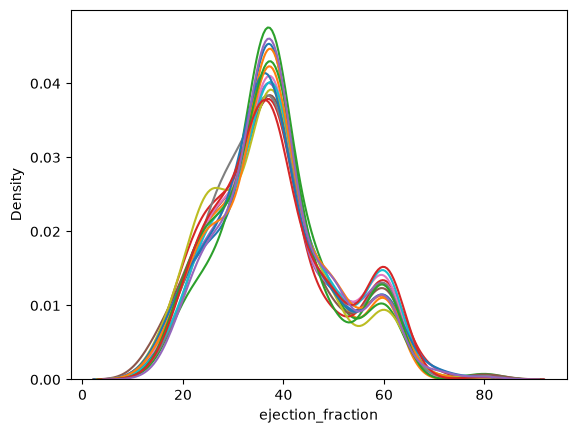

In [31]:
for i in range(15) : 
    sample = df2.sample(frac=1.0, replace = True)
    sns.kdeplot(data = sample, x = "ejection_fraction")

plt.show()